In [1]:
from sklearn.gaussian_process import GaussianProcessRegressor, kernels
import numpy as np
from matplotlib import pyplot as plt
from pathlib import Path
import pickle

In [2]:
saved_dir = Path('/home/hedi/HSCNG/peaks/mock_results_g')
# read the data
# for legacy data, there is nan problems in it, so I redid some of them.

In [3]:
tomo = 3
peaks_results = np.load(saved_dir / f'peaks_results_z{tomo}.npy', allow_pickle=True)
min_results = np.load(saved_dir / f'minimums_results_z{tomo}.npy', allow_pickle=True)

In [6]:
with open(f'/home/hedi/HSCNG/peaks/mock_results_fid/peaks_results_fid_z{tomo}.pkl', 'rb') as f:
    peaks_results_fid = pickle.load(f)

In [8]:
peaks_results_fid[0]

array([-4.73684211e+00, -4.21052632e+00, -3.68421053e+00, -3.15789474e+00,
       -2.63157895e+00, -2.10526316e+00, -1.57894737e+00, -1.05263158e+00,
       -5.26315789e-01, -4.44089210e-16,  5.26315789e-01,  1.05263158e+00,
        1.57894737e+00,  2.10526316e+00,  2.63157895e+00,  3.15789474e+00,
        3.68421053e+00,  4.21052632e+00,  4.73684211e+00])

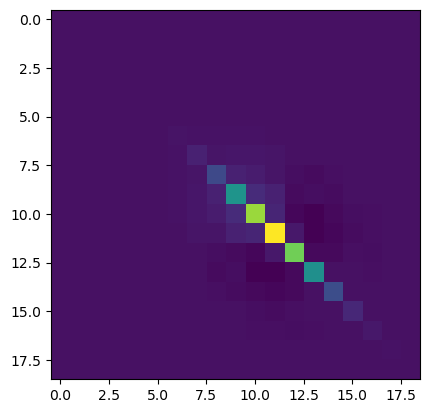

In [11]:
plt.imshow(peaks_results_fid[2])

In [25]:
# x = min_results[0][0]
# s_mean_p = min_results[:,1]
# s_std_p = min_results[:,2]

x = peaks_results[0][0]
s_mean_p = peaks_results[:,1]
s_std_p = peaks_results[:,2]

s_real = peaks_results_fid[1]
std_real = np.diag(peaks_results_fid[2])**0.5

In [9]:
cosmo_pars = np.loadtxt('/home/hedi/HSCNG/data/cosmo_params.txt', skiprows=1)

In [10]:
cosmo_Om = cosmo_pars[:,1]
cosmo_S8 = cosmo_pars[:,3]
cosmo_H0 = cosmo_pars[:,4]

In [11]:
cosmo_Om.min(), cosmo_Om.max(), cosmo_S8.min(), cosmo_S8.max()

(np.float64(0.10721),
 np.float64(0.54725),
 np.float64(0.60228),
 np.float64(0.89867))

In [19]:
X = np.c_[cosmo_Om, cosmo_S8, cosmo_H0]         # order: Om, S8, H0
mid_val = X.mean(axis=0)

X = X - mid_val
Y = s_mean_p

In [20]:
ranges = np.ptp(X, axis=0)

In [21]:
gpr = GaussianProcessRegressor(
    kernel=kernels.RBF(length_scale=ranges, 
    length_scale_bounds=(1e-2, 1e2)),
    alpha=1e-6, normalize_y=True,
    n_restarts_optimizer=10,
    random_state=139
)

In [22]:
gpr.fit(X, Y).kernel_

RBF(length_scale=[0.055, 0.0301, 0.0526])

In [26]:
def plot_gpr_lines(x_t, ys, gif_path, interval=120, real=False):

    from matplotlib.animation import FuncAnimation, PillowWriter
    from IPython.display import Image, display

    fig, ax = plt.subplots(figsize=(6, 4))
    cmap_anim = plt.get_cmap("viridis")

    ymin, ymax = ys.min(), ys.max()
    ax.set_xlim(x.min(), x.max())
    ax.set_ylim(ymin, ymax)

    def update(frame):
        ax.clear()
        ax.set_xlim(x.min(), x.max())
        ax.set_ylim(ymin, ymax)
        for j in range(frame + 1):
            ax.plot(x, ys[j], color=cmap_anim(j / max(1, ys.shape[0] - 1)))
        if real:
            ax.errorbar(x, s_real, yerr=std_real, fmt='o', color='red', label='Real Data')

        ax.set_title(f"Curves: {frame + 1}/{ys.shape[0]}\n(Om={x_t[frame][0] + mid_val[0]:.2f}, S8={x_t[frame][1] + mid_val[1]:.2f}, H0={x_t[frame][2] + mid_val[2]:.2f})")
        ax.set_xlabel("x")

    anim = FuncAnimation(fig, update, frames=ys.shape[0], interval=interval, blit=False)

    anim.save(gif_path, writer=PillowWriter(fps=8))
    plt.close(fig)

    display(Image(filename=str(gif_path)))

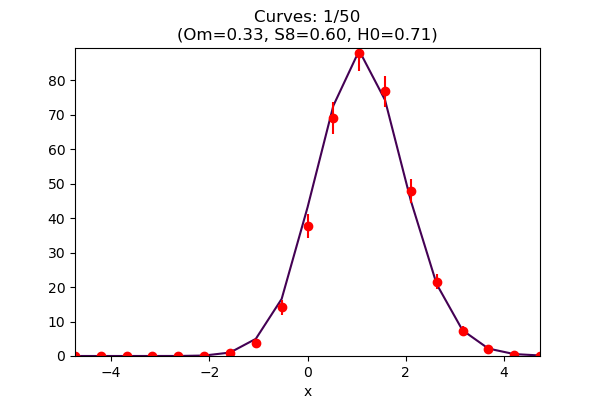

In [28]:
h_t = 0
om_t = 0
s_t = np.linspace(-0.15, 0.15, 50)
x_t = np.c_[om_t*np.ones_like(s_t), s_t, h_t*np.ones_like(s_t)]
ys = gpr.predict(x_t)
gif_path = saved_dir / f"inc_s8_z{tomo}_real.gif"

plot_gpr_lines(x_t, ys, gif_path, real=True)

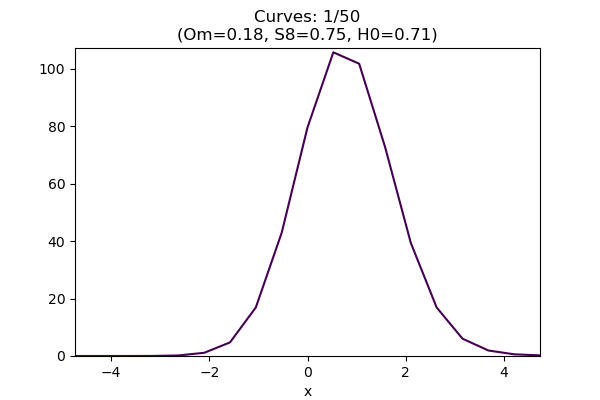

In [13]:
h_t = 0
om_t = np.linspace(-0.15, 0.15, 50)
s_t = 0

x_t = np.c_[om_t, s_t*np.ones_like(om_t), h_t*np.ones_like(om_t)]
ys = gpr.predict(x_t)
gif_path = saved_dir / f"inc_om_z{tomo}.gif"

plot_gpr_lines(x_t, ys, gif_path)

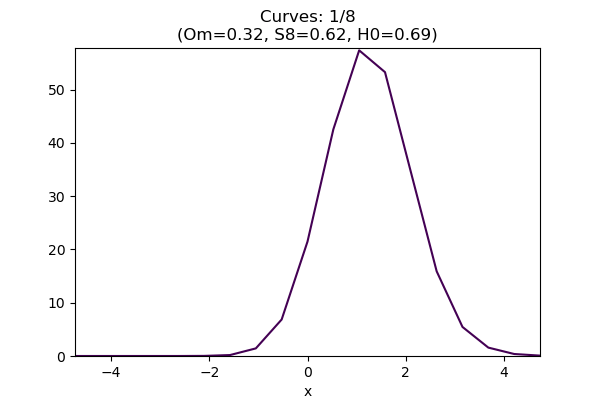

In [25]:
index = (X[:,0] < 0.05) & (X[:,0] > -0.05) & (X[:,2] < 0.05) & (X[:,2] > -0.05)
S_plot = X[index, 1]
Y_plot = Y[index]
sort_index = np.argsort(S_plot)


X_plot = X[index][sort_index]
Y_plot = Y[index][sort_index]
plot_gpr_lines(X_plot, Y_plot, saved_dir / f"real_s8_z{tomo}.gif", interval=1800)

In [40]:
from astropy.cosmology import Planck18

In [ ]:
Om_fid = 0.31
h0_fid = 0.6766
S_fid = Planck18.meta['sigma8'] * np.sqrt(Planck18.Om0 / 0.3)

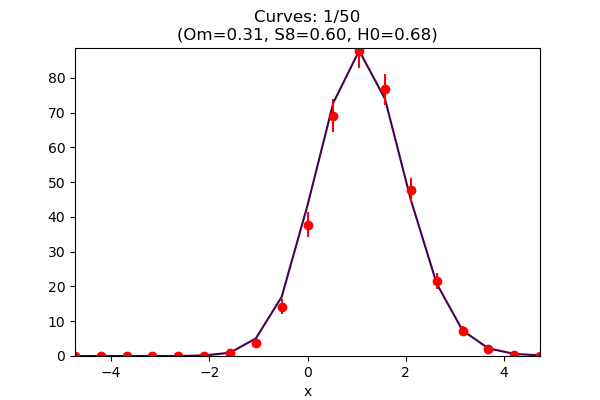

In [57]:
om_t = Om_fid - mid_val[0]
s_t = np.linspace(-0.15, 0.15, 50)
h_t = h0_fid - mid_val[2]

x_t = np.c_[om_t*np.ones_like(s_t), s_t, h_t*np.ones_like(s_t)]

ys = gpr.predict(x_t)
gif_path = saved_dir / f"inc_s8_z{tomo}_real.gif"

plot_gpr_lines(x_t, ys, gif_path, real=True)

In [10]:
def takeout_test(takeout_index, print_kernel=False, **kwargs):
    select = np.arange(len(X)) != takeout_index
    X_train = X[select]
    Y_train = Y[select]

    X_test = X[takeout_index]
    Y_test = Y[takeout_index]
    sig_test = s_std_p[takeout_index]

    default_kwargs = {
        'kernel': kernels.RBF(length_scale=ranges, 
        length_scale_bounds=(1e-2, 1e2)),       # be careful if the optimizer is going to push it to the boundary
        'alpha': 1e-6, 'normalize_y': True,
        'n_restarts_optimizer': 50,
        'random_state': 139
    }
    default_kwargs.update(kwargs)
    gpr = GaussianProcessRegressor(
        **default_kwargs
    )

    gpr.fit(X_train, Y_train).kernel_

    Y_pre = gpr.predict(X_test.reshape(1, -1))

    res = (Y_test - Y_pre) / sig_test
    res = res[np.isnan(res) == False]       # this happens at 0/0

    if print_kernel:
        print(gpr.kernel_)

    return np.sqrt((res**2).mean())

In [17]:
rmse = []
for i in range(len(X)):
    rmse.append(takeout_test(i))

/var/tmp/pbs.580356.idark/ipykernel_50371/854062543.py:26: RuntimeWarning: divide by zero encountered in divide
  res = (Y_test - Y_pre) / sig_test
/var/tmp/pbs.580356.idark/ipykernel_50371/854062543.py:26: RuntimeWarning: invalid value encountered in divide
  res = (Y_test - Y_pre) / sig_test
/var/tmp/pbs.580356.idark/ipykernel_50371/854062543.py:26: RuntimeWarning: divide by zero encountered in divide
  res = (Y_test - Y_pre) / sig_test
/var/tmp/pbs.580356.idark/ipykernel_50371/854062543.py:26: RuntimeWarning: invalid value encountered in divide
  res = (Y_test - Y_pre) / sig_test
/var/tmp/pbs.580356.idark/ipykernel_50371/854062543.py:26: RuntimeWarning: divide by zero encountered in divide
  res = (Y_test - Y_pre) / sig_test
/var/tmp/pbs.580356.idark/ipykernel_50371/854062543.py:26: RuntimeWarning: invalid value encountered in divide
  res = (Y_test - Y_pre) / sig_test
/var/tmp/pbs.580356.idark/ipykernel_50371/854062543.py:26: RuntimeWarning: divide by zero encountered in divide
  r

In [18]:
rmse

[np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf),
 np.float64(inf)]